In [1]:
import warnings

# 忽略所有警告
warnings.filterwarnings('ignore')

In [2]:
import os
import numpy as np
import pandas as pd
import pickle

from sklearn.model_selection import train_test_split, KFold, cross_val_predict
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, precision_score, recall_score, roc_auc_score, roc_curve
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LassoCV
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, classification_report, roc_auc_score, roc_curve
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.svm import SVC
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegressionCV, LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import make_scorer, mean_squared_error, r2_score
from sklearn.metrics import mean_absolute_error, max_error, explained_variance_score

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor, AdaBoostRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import Ridge

import matplotlib.pyplot as plt

In [3]:
df_dir = 'data/ga_data'

In [4]:
# data loading
X_train = pd.read_pickle(os.path.join(df_dir, 'X_train.pkl'))
y_train = pd.read_pickle(os.path.join(df_dir, 'y_train.pkl'))

X_test = pd.read_pickle(os.path.join(df_dir, 'X_test.pkl'))
y_test = pd.read_pickle(os.path.join(df_dir, 'y_test.pkl'))

In [5]:
# get rid of non-numeric columns like "image name"
X_train_numeric = X_train.select_dtypes(include=[np.number])
X_test_numeric = X_test.select_dtypes(include=[np.number])

In [6]:
# standerlization
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_numeric)
X_test_scaled = scaler.transform(X_test_numeric)
# X_train_scaled[:5], X_test_scaled[:5]

Model: ['Linear Regression', 'Random Forest', 'SVM', 'Decision Tree', 'Gradient Boosting', 'K-Nearest Neighbors', 'AdaBoost', 'Ridge Regression']
RMSE: [82.4120376789692, 31.272409596789984, 46.670187139277495, 45.54635182255051, 32.61480432878577, 36.26691686214182, 40.91476760454774, 36.190498905957355]
R2: [-1.14965057430882, 0.690465360180762, 0.3106089340991035, 0.34341076311059426, 0.6633209284141517, 0.5836986303813967, 0.47015755795861913, 0.5854511578152259]
MAE: [29.597217475189026, 21.358845233011046, 36.16656483710993, 28.98188258706113, 22.737990444196654, 25.249749147727425, 34.196480058401136, 26.88222272450716]
MAPE: [18.775727827863758, 13.019248483070827, 20.923762975840283, 17.249396639444033, 13.754611164018366, 15.265569808235584, 21.95773230345046, 16.27348122807878]
Max Error: [2632.6432826453756, 310.52569895370004, 307.9946359962164, 394.7777857, 310.401997000679, 316.01791676, 276.5748731921915, 305.0159072772254]
EVS: [-1.1472971838613324, 0.6904850017565325,

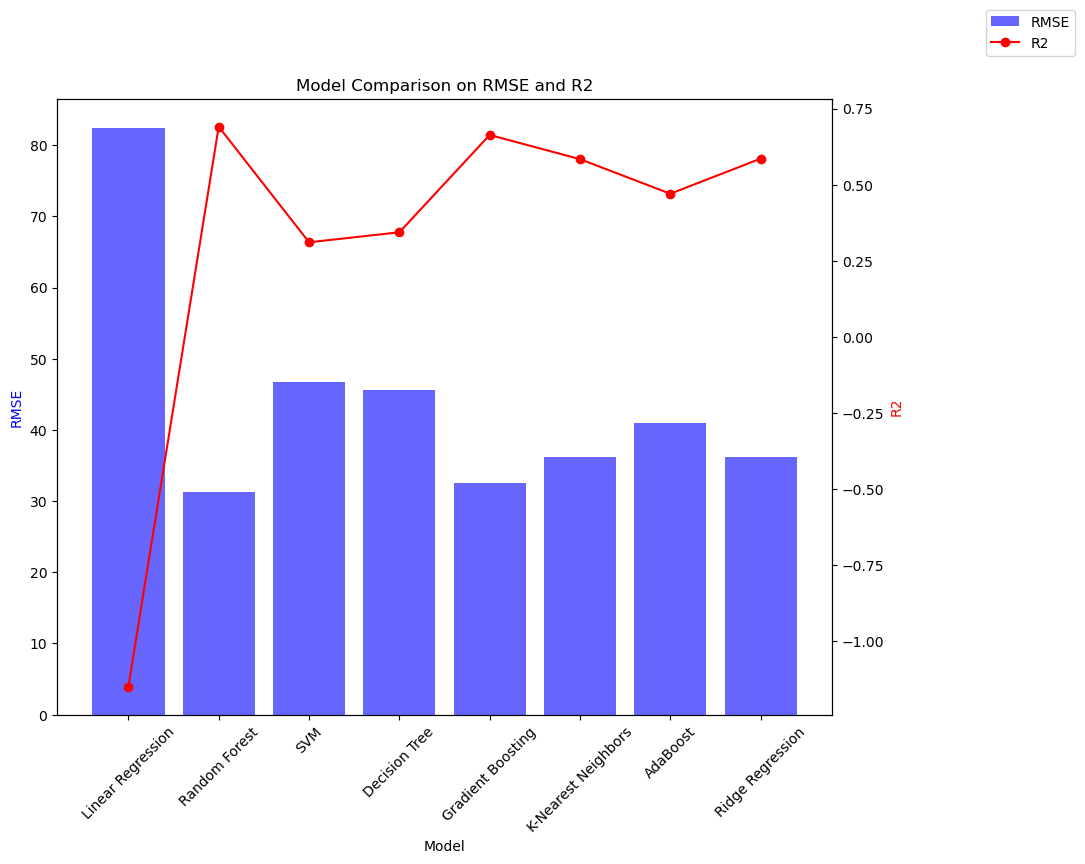

In [7]:
# model selection using 5-fold validation, testset kept for final evaluation
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(random_state=42),
    "SVM": SVR(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    "K-Nearest Neighbors": KNeighborsRegressor(),
    "AdaBoost": AdaBoostRegressor(random_state=42),
    "Ridge Regression": Ridge()
}

kf = KFold(n_splits=5, shuffle=True, random_state=42)

# 6 metrics
results = {
    "Model": [],
    "RMSE": [],
    "R2": [],
    "MAE": [],
    "MAPE": [],
    "Max Error": [],
    "EVS": [] 
}

for name, model in models.items():
    y_preds = cross_val_predict(model, X_train_scaled, y_train, cv=kf)
    mse = mean_squared_error(y_train, y_preds)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_train, y_preds)
    mae = mean_absolute_error(y_train, y_preds)
    max_error_val = max_error(y_train, y_preds)
    evs = explained_variance_score(y_train, y_preds)  
    
    contains_zero = (y_train == 0).any()
    if not contains_zero:
        mape = (np.abs((y_train - y_preds) / y_train).mean()) * 100
    else:
        mape = "undefined (contains zero)"

    results["Model"].append(name)
    results["RMSE"].append(rmse)
    results["R2"].append(r2)
    results["MAE"].append(mae)
    results["MAPE"].append(mape)
    results["Max Error"].append(max_error_val)
    results["EVS"].append(evs)

for key, value in results.items():
    print(f"{key}: {value}")

fig, ax1 = plt.subplots(figsize=(10, 8))
ax2 = ax1.twinx()
ax1.bar(range(len(results["Model"])), results["RMSE"], color='b', alpha=0.6, label='RMSE')
ax2.plot(range(len(results["Model"])), results["R2"], color='r', marker='o', label='R2')

ax1.set_xlabel('Model')
ax1.set_ylabel('RMSE', color='b')
ax2.set_ylabel('R2', color='r')
ax1.set_xticks(range(len(results["Model"])))
ax1.set_xticklabels(results["Model"], rotation=45)
ax1.set_title('Model Comparison on RMSE and R2')

fig.legend(loc='upper right', bbox_to_anchor=(1.15, 1))
plt.show()


#### model selection with 5-fold validation

In [9]:
results_df = pd.DataFrame(results).round(2)
results_df

,Model,RMSE,R2,MAE,MAPE,Max Error,EVS
0,Linear Regression,82.41,-1.15,29.60,18.78,2632.64,-1.15
1,Random Forest,31.27,0.69,21.36,13.02,310.53,0.69
2,SVM,46.67,0.31,36.17,20.92,307.99,0.35
3,Decision Tree,45.55,0.34,28.98,17.25,394.78,0.34
4,Gradient Boosting,32.61,0.66,22.74,13.75,310.40,0.66
5,K-Nearest Neighbors,36.27,0.58,25.25,15.27,316.02,0.58
6,AdaBoost,40.91,0.47,34.20,21.96,276.57,0.49
7,Ridge Regression,36.19,0.59,26.88,16.27,305.02,0.59


### Grid search with 5-fold validation 

In [10]:
from sklearn.model_selection import GridSearchCV

rf_param_grid = {
    'n_estimators': [100, 200, 300],
    'max_features': [1.0, 'sqrt', 'log2'],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

gb_param_grid = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.01, 0.1, 0.2],
    'max_depth': [3, 5, 10],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

rf_model = RandomForestRegressor(random_state=42)
gb_model = GradientBoostingRegressor(random_state=42)

rf_grid_search = GridSearchCV(estimator=rf_model, param_grid=rf_param_grid, cv=kf, n_jobs=-1, scoring='neg_mean_squared_error', verbose=2)
gb_grid_search = GridSearchCV(estimator=gb_model, param_grid=gb_param_grid, cv=kf, n_jobs=-1, scoring='neg_mean_squared_error', verbose=2)

rf_grid_search.fit(X_train_scaled, y_train)
gb_grid_search.fit(X_train_scaled, y_train)

rf_best_params = rf_grid_search.best_params_
gb_best_params = gb_grid_search.best_params_

rf_best_params, gb_best_params

Fitting 5 folds for each of 324 candidates, totalling 1620 fits
Fitting 5 folds for each of 243 candidates, totalling 1215 fits


({'max_depth': 20,
  'max_features': 1.0,
  'min_samples_leaf': 2,
  'min_samples_split': 5,
  'n_estimators': 100},
 {'learning_rate': 0.1,
  'max_depth': 5,
  'min_samples_leaf': 4,
  'min_samples_split': 10,
  'n_estimators': 200})

In [11]:
rf_best_params, gb_best_params

({'max_depth': 20,
  'max_features': 1.0,
  'min_samples_leaf': 2,
  'min_samples_split': 5,
  'n_estimators': 100},
 {'learning_rate': 0.1,
  'max_depth': 5,
  'min_samples_leaf': 4,
  'min_samples_split': 10,
  'n_estimators': 200})

In [12]:
# Update model dictionary with optimized models (5-fold)
models.update({
    "Random Forest OP": RandomForestRegressor(random_state=42, **rf_best_params),
    "Gradient Boosting OP": GradientBoostingRegressor(random_state=42, **gb_best_params)
})

kf = KFold(n_splits=5, shuffle=True, random_state=42)

for name, model in models.items():
    # Ensure no duplicate model entries
    if name not in results["Model"]:
        y_preds = cross_val_predict(model, X_train_scaled, y_train, cv=kf)
        
        mse = mean_squared_error(y_train, y_preds)
        rmse = np.sqrt(mse)
        r2 = r2_score(y_train, y_preds)
        mae = mean_absolute_error(y_train, y_preds)
        max_error_val = max_error(y_train, y_preds)
        evs = explained_variance_score(y_train, y_preds)
        mape = (np.abs((y_train - y_preds) / y_train).mean() * 100) if not contains_zero else "undefined"
        
        results["Model"].append(name)
        results["RMSE"].append(rmse)
        results["R2"].append(r2)
        results["MAE"].append(mae)
        results["MAPE"].append(mape)
        results["Max Error"].append(max_error_val)
        results["EVS"].append(evs)

results_df = pd.DataFrame(results).round(2)
results_df

,Model,RMSE,R2,MAE,MAPE,Max Error,EVS
0,Linear Regression,82.41,-1.15,29.60,18.78,2632.64,-1.15
1,Random Forest,31.27,0.69,21.36,13.02,310.53,0.69
2,SVM,46.67,0.31,36.17,20.92,307.99,0.35
3,Decision Tree,45.55,0.34,28.98,17.25,394.78,0.34
4,Gradient Boosting,32.61,0.66,22.74,13.75,310.40,0.66
5,K-Nearest Neighbors,36.27,0.58,25.25,15.27,316.02,0.58
6,AdaBoost,40.91,0.47,34.20,21.96,276.57,0.49
7,Ridge Regression,36.19,0.59,26.88,16.27,305.02,0.59
8,Random Forest OP,30.93,0.70,21.20,12.88,305.20,0.70
9,Gradient Boosting OP,31.09,0.69,21.29,12.82,285.73,0.69


### RF Lasso 5-fold

In [13]:
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler

rf_params = rf_best_params

rf_model = RandomForestRegressor(**rf_params)
rf_model.fit(X_train_scaled, y_train)

importances = rf_model.feature_importances_

threshold = np.mean(importances)

important_indices = np.where(importances > threshold)[0]
X_train_important = X_train_scaled[:, important_indices]
X_test_important = X_test_scaled[:, important_indices]

lasso_cv = LassoCV(cv=5)
lasso_cv.fit(X_train_important, y_train)

lasso_mask = lasso_cv.coef_ != 0
selected_features = X_train.columns[important_indices][lasso_mask]

selected_features

Index(['original_shape2D_Elongation', 'original_shape2D_MaximumDiameter',
       'original_shape2D_MinorAxisLength', 'original_shape2D_Perimeter',
       'original_shape2D_PerimeterSurfaceRatio',
       'original_shape2D_PixelSurface', 'original_firstorder_10Percentile',
       'original_firstorder_Maximum', 'original_firstorder_Variance',
       'original_glrlm_HighGrayLevelRunEmphasis',
       'original_glrlm_LongRunLowGrayLevelEmphasis',
       'original_glrlm_ShortRunEmphasis',
       'original_glrlm_ShortRunHighGrayLevelEmphasis',
       'original_glszm_HighGrayLevelZoneEmphasis',
       'original_glszm_LargeAreaLowGrayLevelEmphasis',
       'original_glszm_SmallAreaEmphasis',
       'original_glszm_SmallAreaHighGrayLevelEmphasis',
       'original_gldm_DependenceNonUniformity',
       'original_gldm_GrayLevelNonUniformity'],
      dtype='object')

In [14]:
X_train_selected = X_train_scaled[:, important_indices]
X_test_selected = X_test_scaled[:, important_indices]

X_train_rf_l = X_train_selected[:, lasso_mask]
X_test_rf_1 = X_test_selected[:, lasso_mask]

rf_model_selected = RandomForestRegressor(**rf_params)

In [15]:
# Update model dictionary with optimized models (5-fold)
models.update({
    "Random Forest lasso": rf_model_selected
})

kf = KFold(n_splits=5, shuffle=True, random_state=42)

for name, model in models.items():
    # Ensure no duplicate model entries
    if name not in results["Model"]:
        y_preds = cross_val_predict(model, X_train_rf_l, y_train, cv=kf)
        
        mse = mean_squared_error(y_train, y_preds)
        rmse = np.sqrt(mse)
        r2 = r2_score(y_train, y_preds)
        mae = mean_absolute_error(y_train, y_preds)
        max_error_val = max_error(y_train, y_preds)
        evs = explained_variance_score(y_train, y_preds)
        mape = (np.abs((y_train - y_preds) / y_train).mean() * 100) if not contains_zero else "undefined"
        
        results["Model"].append(name)
        results["RMSE"].append(rmse)
        results["R2"].append(r2)
        results["MAE"].append(mae)
        results["MAPE"].append(mape)
        results["Max Error"].append(max_error_val)
        results["EVS"].append(evs)

results_df = pd.DataFrame(results).round(2)
results_df

,Model,RMSE,R2,MAE,MAPE,Max Error,EVS
0,Linear Regression,82.41,-1.15,29.60,18.78,2632.64,-1.15
1,Random Forest,31.27,0.69,21.36,13.02,310.53,0.69
2,SVM,46.67,0.31,36.17,20.92,307.99,0.35
3,Decision Tree,45.55,0.34,28.98,17.25,394.78,0.34
4,Gradient Boosting,32.61,0.66,22.74,13.75,310.40,0.66
5,K-Nearest Neighbors,36.27,0.58,25.25,15.27,316.02,0.58
6,AdaBoost,40.91,0.47,34.20,21.96,276.57,0.49
7,Ridge Regression,36.19,0.59,26.88,16.27,305.02,0.59
8,Random Forest OP,30.93,0.70,21.20,12.88,305.20,0.70
9,Gradient Boosting OP,31.09,0.69,21.29,12.82,285.73,0.69


### GBR Lasso 5-fold

In [16]:
gbr_params = gb_best_params

gbr_model = GradientBoostingRegressor(**gbr_params)
gbr_model.fit(X_train_scaled, y_train)

importances = gbr_model.feature_importances_

threshold = np.mean(importances)

important_indices = np.where(importances > threshold)[0]
X_train_important = X_train_scaled[:, important_indices]
X_test_important = X_test_scaled[:, important_indices]

lasso_cv = LassoCV(cv=5)
lasso_cv.fit(X_train_important, y_train)

lasso_mask = lasso_cv.coef_ != 0
selected_features_gbr = X_train.columns[important_indices][lasso_mask]

selected_features_gbr

Index(['original_shape2D_Elongation', 'original_shape2D_MaximumDiameter',
       'original_shape2D_MinorAxisLength',
       'original_shape2D_PerimeterSurfaceRatio',
       'original_firstorder_10Percentile', 'original_firstorder_Maximum',
       'original_firstorder_Variance', 'original_glcm_Correlation',
       'original_glrlm_HighGrayLevelRunEmphasis',
       'original_glrlm_LongRunLowGrayLevelEmphasis',
       'original_glrlm_ShortRunEmphasis',
       'original_glrlm_ShortRunHighGrayLevelEmphasis',
       'original_glszm_LargeAreaLowGrayLevelEmphasis',
       'original_glszm_SmallAreaEmphasis',
       'original_glszm_SmallAreaHighGrayLevelEmphasis',
       'original_gldm_GrayLevelNonUniformity'],
      dtype='object')

selected features gbr:

       'original_shape2D_Elongation', 'original_shape2D_MinorAxisLength',
       'original_shape2D_PerimeterSurfaceRatio',
       'original_firstorder_10Percentile', 'original_firstorder_Maximum',
       'original_firstorder_Variance', 'original_glcm_Correlation',
       'original_glrlm_HighGrayLevelRunEmphasis',
       'original_glrlm_ShortRunEmphasis',
       'original_glrlm_ShortRunHighGrayLevelEmphasis',
       'original_glszm_HighGrayLevelZoneEmphasis',
       'original_glszm_LargeAreaLowGrayLevelEmphasis',
       'original_glszm_LowGrayLevelZoneEmphasis',
       'original_glszm_SmallAreaEmphasis',
       'original_glszm_SmallAreaHighGrayLevelEmphasis',
       'original_gldm_GrayLevelNonUniformity'

In [17]:
X_train_selected = X_train_scaled[:, important_indices]
X_test_selected = X_test_scaled[:, important_indices]

X_train_gbr_l = X_train_selected[:, lasso_mask]
X_test_gbr_l = X_test_selected[:, lasso_mask]

gb_model_selected = GradientBoostingRegressor(**gbr_params)

In [18]:
# Update model dictionary with optimized models (5-fold)
models.update({
#     "Random Forest lasso": rf_model_selected,
    "GBR lasso": gb_model_selected
})

kf = KFold(n_splits=5, shuffle=True, random_state=42)

for name, model in models.items():
    # Ensure no duplicate model entries
    if name not in results["Model"]:
        y_preds = cross_val_predict(model, X_train_gbr_l, y_train, cv=kf)
        
        mse = mean_squared_error(y_train, y_preds)
        rmse = np.sqrt(mse)
        r2 = r2_score(y_train, y_preds)
        mae = mean_absolute_error(y_train, y_preds)
        max_error_val = max_error(y_train, y_preds)
        evs = explained_variance_score(y_train, y_preds)
        mape = (np.abs((y_train - y_preds) / y_train).mean() * 100) if not contains_zero else "undefined"
        
        results["Model"].append(name)
        results["RMSE"].append(rmse)
        results["R2"].append(r2)
        results["MAE"].append(mae)
        results["MAPE"].append(mape)
        results["Max Error"].append(max_error_val)
        results["EVS"].append(evs)

results_df = pd.DataFrame(results).round(2)
results_df

,Model,RMSE,R2,MAE,MAPE,Max Error,EVS
0,Linear Regression,82.41,-1.15,29.60,18.78,2632.64,-1.15
1,Random Forest,31.27,0.69,21.36,13.02,310.53,0.69
2,SVM,46.67,0.31,36.17,20.92,307.99,0.35
3,Decision Tree,45.55,0.34,28.98,17.25,394.78,0.34
4,Gradient Boosting,32.61,0.66,22.74,13.75,310.40,0.66
5,K-Nearest Neighbors,36.27,0.58,25.25,15.27,316.02,0.58
6,AdaBoost,40.91,0.47,34.20,21.96,276.57,0.49
7,Ridge Regression,36.19,0.59,26.88,16.27,305.02,0.59
8,Random Forest OP,30.93,0.70,21.20,12.88,305.20,0.70
9,Gradient Boosting OP,31.09,0.69,21.29,12.82,285.73,0.69


### RF RFE 5-fold

In [20]:
from sklearn.feature_selection import RFECV

rf_model_for_rfe = RandomForestRegressor(**rf_params)

rfe = RFECV(estimator=rf_model_for_rfe, step=1, cv=5, scoring='neg_mean_squared_error', min_features_to_select=1, verbose=0)

rfe.fit(X_train_scaled, y_train)

# selected_features_rfe = X_train.columns[rfe.support_]
# selected_features_rfe, rfe.ranking_

RFECV(cv=5,
      estimator=RandomForestRegressor(max_depth=20, min_samples_leaf=2,
                                      min_samples_split=5),
      scoring='neg_mean_squared_error')

In [21]:
selected_features_rfe = X_train_numeric.columns[rfe.support_]
selected_features_rfe, rfe.ranking_

(Index(['original_shape2D_Elongation', 'original_shape2D_MaximumDiameter',
        'original_shape2D_MeshSurface', 'original_shape2D_MinorAxisLength',
        'original_shape2D_PerimeterSurfaceRatio',
        'original_firstorder_10Percentile', 'original_firstorder_Range',
        'original_firstorder_RootMeanSquared', 'original_firstorder_Skewness',
        'original_firstorder_Variance', 'original_glcm_Correlation',
        'original_glrlm_HighGrayLevelRunEmphasis', 'original_glrlm_RunEntropy',
        'original_glrlm_RunLengthNonUniformity',
        'original_glrlm_ShortRunEmphasis',
        'original_glrlm_ShortRunHighGrayLevelEmphasis',
        'original_glszm_GrayLevelVariance',
        'original_glszm_HighGrayLevelZoneEmphasis',
        'original_glszm_LargeAreaHighGrayLevelEmphasis',
        'original_glszm_LargeAreaLowGrayLevelEmphasis',
        'original_glszm_LowGrayLevelZoneEmphasis',
        'original_glszm_SmallAreaEmphasis',
        'original_glszm_SmallAreaHighGrayLevel

In [22]:
rfe.cv_results_

{'mean_test_score': array([-3071.31024471, -1492.73406446, -1381.69639656, -1346.92141185,
        -1269.57426418, -1177.78140255, -1156.10392189, -1142.56238243,
        -1144.95635524, -1129.43512374, -1080.99598781, -1083.7021646 ,
        -1096.5322081 , -1088.2832725 , -1077.64401717, -1062.78276479,
        -1056.03069451, -1047.26416409, -1035.44237685, -1047.19281716,
        -1035.45337632, -1014.68455075, -1014.31904908, -1019.49273094,
        -1024.29953425, -1013.78642021, -1033.19372335, -1018.84730297,
        -1028.77183691, -1016.22689903, -1022.6213329 , -1028.02023086,
        -1018.89395181, -1015.23918454, -1026.69851883, -1023.46690605,
        -1014.32313092, -1041.10882805, -1034.33321555, -1030.37848149,
        -1027.99064189, -1033.7449226 , -1030.1603249 , -1018.1358859 ,
        -1032.9269677 , -1038.1012851 , -1042.16491418, -1025.40503904,
        -1023.6700625 , -1046.83402623, -1039.37010191, -1027.23074726,
        -1022.17384859, -1030.51637028, -1031

In [23]:
X_train_selected_rf = X_train_scaled[:, rfe.support_]
X_test_selected_rf = X_test_scaled[:, rfe.support_]

rf_model_retrained = RandomForestRegressor(**rf_params)
rf_model_retrained.fit(X_train_selected_rf, y_train)

RandomForestRegressor(max_depth=20, min_samples_leaf=2, min_samples_split=5)

In [24]:
models.update({
    "Random Forest RFE": rf_model_retrained
})

kf = KFold(n_splits=5, shuffle=True, random_state=42)

for name, model in models.items():
    # Ensure no duplicate model entries
    if name not in results["Model"]:
        y_preds = cross_val_predict(model, X_train_selected_rf, y_train, cv=kf)
        
        mse = mean_squared_error(y_train, y_preds)
        rmse = np.sqrt(mse)
        r2 = r2_score(y_train, y_preds)
        mae = mean_absolute_error(y_train, y_preds)
        max_error_val = max_error(y_train, y_preds)
        evs = explained_variance_score(y_train, y_preds)
        mape = (np.abs((y_train - y_preds) / y_train).mean() * 100) if not contains_zero else "undefined"
        
        results["Model"].append(name)
        results["RMSE"].append(rmse)
        results["R2"].append(r2)
        results["MAE"].append(mae)
        results["MAPE"].append(mape)
        results["Max Error"].append(max_error_val)
        results["EVS"].append(evs)

results_df = pd.DataFrame(results).round(2)
results_df

,Model,RMSE,R2,MAE,MAPE,Max Error,EVS
0,Linear Regression,82.41,-1.15,29.60,18.78,2632.64,-1.15
1,Random Forest,31.27,0.69,21.36,13.02,310.53,0.69
2,SVM,46.67,0.31,36.17,20.92,307.99,0.35
3,Decision Tree,45.55,0.34,28.98,17.25,394.78,0.34
4,Gradient Boosting,32.61,0.66,22.74,13.75,310.40,0.66
5,K-Nearest Neighbors,36.27,0.58,25.25,15.27,316.02,0.58
6,AdaBoost,40.91,0.47,34.20,21.96,276.57,0.49
7,Ridge Regression,36.19,0.59,26.88,16.27,305.02,0.59
8,Random Forest OP,30.93,0.70,21.20,12.88,305.20,0.70
9,Gradient Boosting OP,31.09,0.69,21.29,12.82,285.73,0.69


### GBR RFE 5-fold

In [25]:
gb_model_for_rfe = GradientBoostingRegressor(**gbr_params)

rfe = RFECV(estimator=gb_model_for_rfe, step=1, cv=5, scoring='neg_mean_squared_error', min_features_to_select=1, verbose=0)

rfe.fit(X_train_scaled, y_train)

# selected_features_rfe = X_train.columns[rfe.support_]
# selected_features_rfe, rfe.ranking_

RFECV(cv=5,
      estimator=GradientBoostingRegressor(max_depth=5, min_samples_leaf=4,
                                          min_samples_split=10,
                                          n_estimators=200),
      scoring='neg_mean_squared_error')

In [26]:
selected_features_rfe = X_train_numeric.columns[rfe.support_]
selected_features_rfe, rfe.ranking_

(Index(['original_shape2D_Elongation', 'original_shape2D_MajorAxisLength',
        'original_shape2D_MaximumDiameter', 'original_shape2D_MinorAxisLength',
        'original_shape2D_Perimeter', 'original_shape2D_PerimeterSurfaceRatio',
        'original_shape2D_PixelSurface', 'original_shape2D_Sphericity',
        'original_firstorder_10Percentile', 'original_firstorder_Energy',
        'original_firstorder_Kurtosis', 'original_firstorder_Maximum',
        'original_firstorder_MeanAbsoluteDeviation', 'original_firstorder_Mean',
        'original_firstorder_Median', 'original_firstorder_Minimum',
        'original_firstorder_Range',
        'original_firstorder_RobustMeanAbsoluteDeviation',
        'original_firstorder_RootMeanSquared', 'original_firstorder_Skewness',
        'original_firstorder_Variance', 'original_glcm_ClusterShade',
        'original_glcm_Correlation', 'original_glcm_Imc1', 'original_glcm_Idmn',
        'original_glrlm_GrayLevelVariance',
        'original_glrlm_High

In [27]:
X_train_selected_gbr = X_train_scaled[:, rfe.support_]
X_test_selected_gbr = X_test_scaled[:, rfe.support_]

gb_model_retrained = GradientBoostingRegressor(**gbr_params)
gb_model_retrained.fit(X_train_selected_gbr, y_train)

GradientBoostingRegressor(max_depth=5, min_samples_leaf=4, min_samples_split=10,
                          n_estimators=200)

In [28]:
models.update({
#     "Random Forest RFE": rf_model_retrained,
    "GBR RFE": gb_model_retrained
})

kf = KFold(n_splits=5, shuffle=True, random_state=42)

for name, model in models.items():
    # Ensure no duplicate model entries
    if name not in results["Model"]:
        y_preds = cross_val_predict(model, X_train_selected_gbr, y_train, cv=kf)
        
        mse = mean_squared_error(y_train, y_preds)
        rmse = np.sqrt(mse)
        r2 = r2_score(y_train, y_preds)
        mae = mean_absolute_error(y_train, y_preds)
        max_error_val = max_error(y_train, y_preds)
        evs = explained_variance_score(y_train, y_preds)
        mape = (np.abs((y_train - y_preds) / y_train).mean() * 100) if not contains_zero else "undefined"
        
        results["Model"].append(name)
        results["RMSE"].append(rmse)
        results["R2"].append(r2)
        results["MAE"].append(mae)
        results["MAPE"].append(mape)
        results["Max Error"].append(max_error_val)
        results["EVS"].append(evs)

results_df = pd.DataFrame(results).round(2)
results_df

,Model,RMSE,R2,MAE,MAPE,Max Error,EVS
0,Linear Regression,82.41,-1.15,29.60,18.78,2632.64,-1.15
1,Random Forest,31.27,0.69,21.36,13.02,310.53,0.69
2,SVM,46.67,0.31,36.17,20.92,307.99,0.35
3,Decision Tree,45.55,0.34,28.98,17.25,394.78,0.34
4,Gradient Boosting,32.61,0.66,22.74,13.75,310.40,0.66
5,K-Nearest Neighbors,36.27,0.58,25.25,15.27,316.02,0.58
6,AdaBoost,40.91,0.47,34.20,21.96,276.57,0.49
7,Ridge Regression,36.19,0.59,26.88,16.27,305.02,0.59
8,Random Forest OP,30.93,0.70,21.20,12.88,305.20,0.70
9,Gradient Boosting OP,31.09,0.69,21.29,12.82,285.73,0.69


### lasso 1 rf

In [30]:
feature_names = X_train_numeric.columns

rf_params = rf_best_params

X_train_scaled = pd.DataFrame(X_train_scaled, columns=feature_names)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=feature_names)

In [31]:
lasso = LassoCV(cv=5, random_state=43, n_alphas=100, eps=0.001).fit(X_train_scaled, y_train)
important_features = X_train_scaled.columns[lasso.coef_ != 0]
print(len(important_features))

X_train_lasso = X_train_scaled[important_features]
X_test_lasso = X_test_scaled[important_features]

rf = RandomForestRegressor(**rf_params)

42


### lasso 1 gbr

In [32]:
gbr = GradientBoostingRegressor(**gbr_params)

In [33]:
models.update({
    "Random Forest lasso only": rf,
    "GBR lasso only": gbr
})

kf = KFold(n_splits=5, shuffle=True, random_state=42)

for name, model in models.items():
    # Ensure no duplicate model entries
    if name not in results["Model"]:
        y_preds = cross_val_predict(model, X_train_lasso, y_train, cv=kf)
        
        mse = mean_squared_error(y_train, y_preds)
        rmse = np.sqrt(mse)
        r2 = r2_score(y_train, y_preds)
        mae = mean_absolute_error(y_train, y_preds)
        max_error_val = max_error(y_train, y_preds)
        evs = explained_variance_score(y_train, y_preds)
        mape = (np.abs((y_train - y_preds) / y_train).mean() * 100) if not contains_zero else "undefined"
        
        results["Model"].append(name)
        results["RMSE"].append(rmse)
        results["R2"].append(r2)
        results["MAE"].append(mae)
        results["MAPE"].append(mape)
        results["Max Error"].append(max_error_val)
        results["EVS"].append(evs)

results_df = pd.DataFrame(results).round(2)
results_df

,Model,RMSE,R2,MAE,MAPE,Max Error,EVS
0,Linear Regression,82.41,-1.15,29.60,18.78,2632.64,-1.15
1,Random Forest,31.27,0.69,21.36,13.02,310.53,0.69
2,SVM,46.67,0.31,36.17,20.92,307.99,0.35
3,Decision Tree,45.55,0.34,28.98,17.25,394.78,0.34
4,Gradient Boosting,32.61,0.66,22.74,13.75,310.40,0.66
5,K-Nearest Neighbors,36.27,0.58,25.25,15.27,316.02,0.58
6,AdaBoost,40.91,0.47,34.20,21.96,276.57,0.49
7,Ridge Regression,36.19,0.59,26.88,16.27,305.02,0.59
8,Random Forest OP,30.93,0.70,21.20,12.88,305.20,0.70
9,Gradient Boosting OP,31.09,0.69,21.29,12.82,285.73,0.69


#### Pick the best models

In [36]:
min_rmse = results_df['RMSE'].min()

threshold = min_rmse * 1.01

selected_models = results_df[results_df['RMSE'] <= threshold]

selected_models

,Model,RMSE,R2,MAE,MAPE,Max Error,EVS
8,Random Forest OP,30.93,0.7,21.20,12.88,305.20,0.7
12,Random Forest RFE,30.76,0.7,21.03,12.75,310.07,0.7
13,GBR RFE,30.82,0.7,21.06,12.63,295.57,0.7


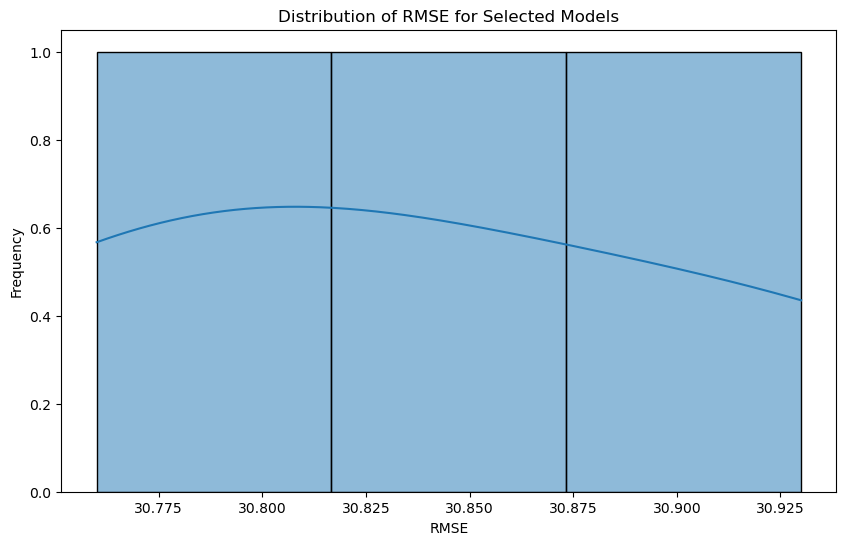

In [37]:
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.histplot(selected_models['RMSE'], kde=True)
plt.title('Distribution of RMSE for Selected Models')
plt.xlabel('RMSE')
plt.ylabel('Frequency')
plt.show()

### Kruskal-Wallis test

In [38]:
from scipy.stats import kruskal

# Extracting RMSE values for each model for the Kruskal-Wallis test
# Assuming each row in selected_models represents an independent measurement of RMSE for the models
groups = [group['RMSE'].values for name, group in selected_models.groupby('Model')]

# Perform the Kruskal-Wallis H-test
stat, p_value = kruskal(*groups)
stat, p_value


(2.0, 0.36787944117144245)

### models have no significant statistical difference.

In [39]:
selected_models

,Model,RMSE,R2,MAE,MAPE,Max Error,EVS
8,Random Forest OP,30.93,0.7,21.20,12.88,305.20,0.7
12,Random Forest RFE,30.76,0.7,21.03,12.75,310.07,0.7
13,GBR RFE,30.82,0.7,21.06,12.63,295.57,0.7


### final evaluation using testset

In [47]:
rfop = RandomForestRegressor(random_state=42, **rf_params)
rfop.fit(X_train_scaled, y_train)
rf_rfe = rf_model_retrained
gbr_rfe = gb_model_retrained

In [48]:
models_final = {
#     "Random Forest": rf,
    "Random Forest OP": rfop,
#     "Gradient Boosting OP": gbrop,
#     "Random Forest with RFE":rf_model_retrained,
#     "GBR with RFE":gb_model_retrained
}

results_final = {
    "Model": [],
    "RMSE": [],
    "R2": [],
    "MAE": [],
    "MAPE": [],
    "Max Error": [],
    "EVS": []
}

for name, model in models_final.items():
    y_preds = model.predict(X_test_scaled)

    mse = mean_squared_error(y_test, y_preds)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_preds)
    mae = mean_absolute_error(y_test, y_preds)
    max_error_val = max_error(y_test, y_preds)
    evs = explained_variance_score(y_test, y_preds)
    
    contains_zero = (y_test == 0).any()
    if not contains_zero:
        mape = (np.abs((y_test - y_preds) / y_test).mean()) * 100
    else:
        mape = "undefined (contains zero)"
    
    results_final["Model"].append(name)
    results_final["RMSE"].append(rmse)
    results_final["R2"].append(r2)
    results_final["MAE"].append(mae)
    results_final["MAPE"].append(mape)
    results_final["Max Error"].append(max_error_val)
    results_final["EVS"].append(evs)

In [49]:
name = "Random Forest with RFE"
model = rf_rfe

y_preds = model.predict(X_test_selected_rf)

mse = mean_squared_error(y_test, y_preds)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_preds)
mae = mean_absolute_error(y_test, y_preds)
max_error_val = max_error(y_test, y_preds)
evs = explained_variance_score(y_test, y_preds)
    
contains_zero = (y_test == 0).any()
if not contains_zero:
    mape = (np.abs((y_test - y_preds) / y_test).mean()) * 100
else:
    mape = "undefined (contains zero)"
    
results_final["Model"].append(name)
results_final["RMSE"].append(rmse)
results_final["R2"].append(r2)
results_final["MAE"].append(mae)
results_final["MAPE"].append(mape)
results_final["Max Error"].append(max_error_val)
results_final["EVS"].append(evs)

In [50]:
name = "GBR with RFE"
model = gbr_rfe

y_preds = model.predict(X_test_selected_gbr)

mse = mean_squared_error(y_test, y_preds)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_preds)
mae = mean_absolute_error(y_test, y_preds)
max_error_val = max_error(y_test, y_preds)
evs = explained_variance_score(y_test, y_preds)
    
contains_zero = (y_test == 0).any()
if not contains_zero:
    mape = (np.abs((y_test - y_preds) / y_test).mean()) * 100
else:
    mape = "undefined (contains zero)"
    
results_final["Model"].append(name)
results_final["RMSE"].append(rmse)
results_final["R2"].append(r2)
results_final["MAE"].append(mae)
results_final["MAPE"].append(mape)
results_final["Max Error"].append(max_error_val)
results_final["EVS"].append(evs)

In [51]:
results_final_df = pd.DataFrame(results_final).round(2)
results_final_df

,Model,RMSE,R2,MAE,MAPE,Max Error,EVS
0,Random Forest OP,31.46,0.69,21.42,12.35,202.03,0.69
1,Random Forest with RFE,31.38,0.69,21.23,12.23,198.13,0.70
2,GBR with RFE,30.72,0.71,21.10,12.15,193.21,0.71


In [54]:
groups = [group['RMSE'].values for name, group in results_final_df.groupby('Model')]

# Perform the Kruskal-Wallis H-test
stat, p_value = kruskal(*groups)
stat, p_value


(2.0, 0.36787944117144245)

#### No significant statistical difference.

Predictions

In [55]:
final_model = gb_model_retrained
predictions = final_model.predict(X_test_selected_gbr)

re = pd.DataFrame({
    'Actual': y_test,
    'Predicted': predictions
})

re.head()

,Actual,Predicted
137,224.702946,210.624929
608,154.332004,124.583883
554,242.931286,186.139398
789,143.388168,135.430176
89,81.905495,85.640680
